# 🛍️ Recomendaciones para clientes nuevos: baseline y primer modelo
**Lookwise Data Lab** · Sistema de recomendación para clientes nuevos de H&M (e-commerce)
**Autora:** Margot Huaman Quispe · **Fase:** Modelado
**Datos:** muestra p10 de H&M (10% de los clientes online, historial completo) · 20/09/2018 – 22/09/2020

---

## 📌 Resumen ejecutivo

| | Hallazgo | Implicancia para H&M |
|---|---|---|
| 1 | **1 de cada 10 compradores semanales es nuevo** (437 de 4.162 en la semana de test) | Una parte relevante de las ventas depende de clientes de los que no sabemos nada |
| 2 | Mostrando las 12 prendas más vendidas de la semana, **solo ~5 de cada 100 clientes nuevos** encuentran algo que compran | Más del 95% de los clientes nuevos no encuentra nada relevante: conversión perdida |
| 3 | **Actualizar la lista cada semana casi triplica los aciertos** frente a usar los más vendidos históricos (6,97% vs 2,45%) | Mejora inmediata y sin costo: la moda cambia rápido |
| 4 | **Modelo 1 (por edad):** ver el veredicto automático de la sección 4.4 | Personalización desde la primera visita, usando un dato que el cliente informa al registrarse |

**Baseline oficial del equipo:** popularidad de los últimos 7 días → **MAP@12 = 0,0083 · Hit Rate@12 = 6,97% (todos) · 4,58% (fríos)**. Todo modelo del equipo debe superar estos valores.

---

## 🎯 Problema de negocio
Un cliente nuevo no tiene historial, por lo que la tienda no sabe qué mostrarle. Si en su primera visita no encuentra nada que le interese, se va sin comprar: **se pierde la venta y el costo de haberlo atraído**. Este notebook construye la **vara de medición** del proyecto y prueba la primera solución personalizada para ese cliente.

## 📏 Del KPI de negocio a la métrica técnica (detalle en la sección 2.3)
| KPI de negocio (lo que ve la dirección) | Cómo lo aproximamos offline | Métrica técnica |
|---|---|---|
| **KPI principal: conversión de clientes nuevos** | % de clientes nuevos que compró al menos 1 de las 12 prendas recomendadas | **Hit Rate@12 en fríos** |
| **KPI secundario: productos por pedido** | Qué parte de lo que el cliente compró estaba en la recomendación | **Recall@12** |
| **Experiencia / engagement** | ¿Lo que compran aparece arriba en la lista? ¿Cuánto del espacio de la vitrina se aprovecha? | **MAP@12** (métrica principal) y **Precision@12** |
| **Salud del catálogo** | ¿Recomendamos siempre lo mismo o damos visibilidad a más prendas? | **Prendas distintas recomendadas** (diversidad) |

> **¿Por qué no un test A/B?** Un A/B necesita mostrar recomendaciones a clientes reales en la tienda en vivo. Trabajamos con datos históricos y sin acceso a la web de H&M ni a datos de visitas. Por eso evaluamos **offline**, simulando el uso real con un corte temporal. El A/B queda como paso de validación para cuando la empresa implemente el sistema.

## 🧭 Contenido
1. Preparación y verificación de los datos
2. Diseño de la evaluación: corte temporal, clientes fríos y métricas
3. Baseline: ¿qué puede hacer H&M hoy sin ciencia de datos?
4. Modelo 1: popularidad por tramo de edad (Hipótesis H1)
5. Resumen de resultados y exportación para el dashboard
6. Conclusiones, recomendaciones y próximos pasos

## ✅ Decisiones del equipo que aplica este notebook (tabla de decisiones del EDA)
| # | Decisión | Cómo se aplica acá |
|---|---|---|
| 1 | Test: 16 al 22/09/2020; train hasta el 15/09 | Sección 2.1 |
| 2 | Marzo a mayo 2020 se conservan en train | No se filtra ningún período |
| 3 | Duplicados: se conservan las filas originales | Una compra repetida cuenta como más demanda de esa prenda |
| 4 | Edad vacía: no se imputa | Grupo propio "sin edad" (sección 4) |
| 5 | Variables de cliente: solo la edad | No se usan FN, Active, postal_code, club_member_status ni fashion_news_frequency |
| 7 | Artículos ausentes en el train | Se reporta un escenario de diagnóstico (sección 3.2) |
| 8 | Segmento nuevo por tramo de edad | Sección 4.2 |
| 9 | Baseline: popularidad histórica y reciente | Sección 3, ventana elegida en validación |

> **Para reproducir:** cambiar `BASE` en la celda 1.1 por la carpeta local de la muestra `p10` y ejecutar *Run All*. Los datos no se suben al repositorio.

---
# 1. Preparación y verificación de los datos

**Qué hacemos:** cargamos las tres tablas (transacciones, clientes y artículos) y verificamos automáticamente que coincidan con el EDA del equipo.

**Por qué:** si cada integrante trabajara con datos distintos, los resultados no serían comparables. Verificar primero garantiza la **reproducibilidad**.

**Por qué parquet y la muestra p10 (y no el CSV completo):** el dataset completo tiene más de 31 millones de filas y no todas las computadoras del equipo pueden procesarlo. La muestra se tomó **por cliente** (no por filas al azar) para conservar el historial completo de cada uno, que es lo que necesita un recomendador. El EDA comprobó que es representativa del total online.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Rutas ---
BASE = "E:/Descargas_Henry/PF_HM/datos/p10"   # <- carpeta local de la muestra p10 (no se sube al repo)
FIG_DIR = "../reports/figures"                # gráficos para la presentación
OUT_DIR = "../reports"                         # tablas para el dashboard (Power BI)
os.makedirs(FIG_DIR, exist_ok=True)

# --- Estilo de gráficos (consistente en todo el proyecto) ---
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b4b3ad"
TEXTO, TEXTO2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d6d5cf", "axes.labelcolor": TEXTO2,
    "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "legend.frameon": False,
})

def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")

def rotular_barras(ax, barras, fmt):
    for b in barras:
        ax.annotate(fmt(b.get_height()), (b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                    fontsize=9, color=TEXTO)

In [2]:
trans = pd.read_parquet(f"{BASE}/transactions.parquet")
cust  = pd.read_parquet(f"{BASE}/customers.parquet")
art   = pd.read_parquet(f"{BASE}/articles.parquet")
trans["t_dat"] = pd.to_datetime(trans["t_dat"])   # la fecha viene como texto

# Verificación automática contra lo documentado en el EDA del equipo
esperado = {"transacciones": (2226486, 5), "clientes": (110252, 7), "artículos": (105542, 25)}
obtenido = {"transacciones": trans.shape, "clientes": cust.shape, "artículos": art.shape}
for tabla in esperado:
    ok = "✅" if esperado[tabla] == obtenido[tabla] else "⚠️ DIFERENTE AL EDA"
    print(f"{tabla:<14} {str(obtenido[tabla]):<16} {ok}")
print("Período:", trans["t_dat"].min().date(), "→", trans["t_dat"].max().date())
print("Canales de venta:", sorted(trans["sales_channel_id"].unique()), "(2 = online)")

transacciones  (2226486, 5)     ✅
clientes       (110252, 7)      ✅
artículos      (105542, 25)     ✅
Período: 2018-09-20 → 2020-09-22
Canales de venta: [np.int64(2)] (2 = online)


### 🔎 Interpretación
- La muestra contiene **2.226.486 transacciones online, 110.252 clientes y 105.542 artículos** (20/09/2018 – 22/09/2020), en **coincidencia exacta** con el EDA: todas las integrantes trabajan sobre la misma base.
- En promedio cada cliente hizo ~20 compras, pero la mediana es 7 (EDA): **la actividad está muy concentrada** en pocos clientes frecuentes.

**💼 Implicancia:** un sistema que solo aprende del historial favorece a los clientes frecuentes y deja sin respuesta a los nuevos. Por eso necesitamos estrategias que **no dependan del historial**.

---
# 2. Diseño de la evaluación
Antes de construir modelos definimos **cómo los vamos a juzgar**. Esta sección es la base de todo el proyecto: si la evaluación está mal diseñada, cualquier resultado es engañoso.

## 2.1 Corte temporal: train, validación y test

**Qué hacemos:** dividimos los datos por fecha.
- **Train** (hasta el 15/09/2020): el pasado del que aprende el modelo.
- **Validación** (09 al 15/09/2020, dentro del train): un *simulacro* para tomar decisiones (por ejemplo, qué ventana usar) sin tocar el test.
- **Test** (16 al 22/09/2020): el examen final, que el modelo nunca ve.

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Corte por fecha** | Simula el uso real: se recomienda hoy y se mide qué compran después | **Corte aleatorio:** el modelo vería compras del futuro (*leakage*) y el resultado sería artificialmente alto |
| **Test de 7 días** | Es la regla de la competencia de H&M en Kaggle y el horizonte real de una campaña semanal | **30 días:** mezcla tendencias que cambian dentro del mes; además dejaría menos historial reciente para aprender |
| **Última semana del dataset** | Es el período más reciente y "normal" | **Marzo–abril 2020:** son meses atípicos (pandemia); el EDA los conserva en train pero no sirven como test representativo |
| **Validación separada** | Permite elegir parámetros sin mirar el examen | **Elegir mirando el test:** es como ver las respuestas antes del examen |

In [3]:
# Corte fijado por el grupo: train hasta el 15/9/2020, test del 16 al 22/9/2020
CORTE = pd.Timestamp("2020-09-16")
VAL   = CORTE - pd.Timedelta(days=7)          # validación: 9 al 15/9 (dentro del train)

train = trans[trans["t_dat"] < CORTE]
test  = trans[trans["t_dat"] >= CORTE]

resumen_corte = pd.DataFrame({
    "Período": [f"{train['t_dat'].min().date()} → {train['t_dat'].max().date()}",
                f"{VAL.date()} → {(CORTE - pd.Timedelta(days=1)).date()}",
                f"{test['t_dat'].min().date()} → {test['t_dat'].max().date()}"],
    "Compras": [len(train), int((train["t_dat"] >= VAL).sum()), len(test)],
}, index=["Train", "  Validación (dentro del train)", "Test"])
resumen_corte["% del total"] = (resumen_corte["Compras"] / len(trans) * 100).round(2)
resumen_corte

,Período,Compras,% del total
Train,2018-09-20 → 2020-09-15,2210154,99.27
Validación (dentro del train),2020-09-09 → 2020-09-15,17519,0.79
Test,2020-09-16 → 2020-09-22,16332,0.73


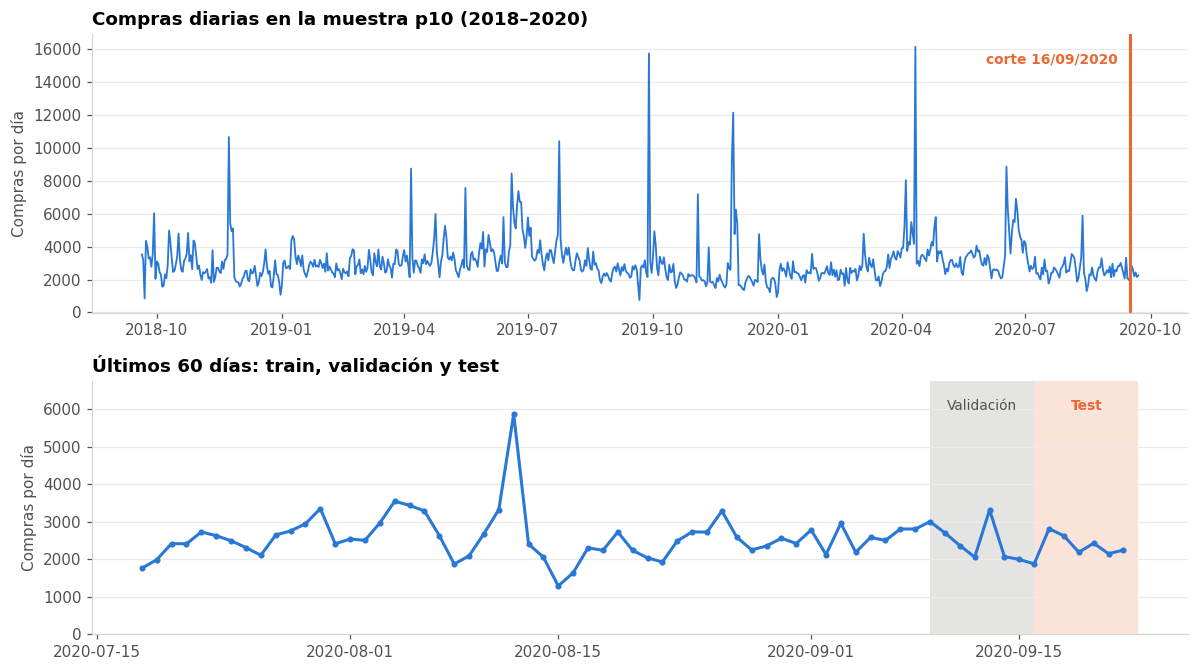

In [4]:
# Gráfico: compras diarias y dónde cae el corte
diarias = trans.groupby("t_dat").size()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), gridspec_kw={"height_ratios": [1.1, 1]})
ax1.plot(diarias.index, diarias.values, color=AZUL, lw=1.2)
ax1.axvline(CORTE, color=NARANJA, lw=2)
ax1.annotate("corte 16/09/2020", (CORTE, diarias.max()), xytext=(-8, -4), textcoords="offset points",
             ha="right", va="top", color=NARANJA, fontsize=9, fontweight="bold")
ax1.set_title("Compras diarias en la muestra p10 (2018–2020)")
ax1.set_ylabel("Compras por día")

zoom = diarias[diarias.index >= CORTE - pd.Timedelta(days=60)]
ax2.plot(zoom.index, zoom.values, color=AZUL, lw=2, marker="o", ms=3)
ax2.axvspan(VAL, CORTE, color=GRIS, alpha=0.35, lw=0)
ax2.axvspan(CORTE, zoom.index.max() + pd.Timedelta(days=1), color=NARANJA, alpha=0.18, lw=0)
ax2.text(VAL + pd.Timedelta(days=3.5), zoom.max() * 1.02, "Validación", ha="center", fontsize=9, color=TEXTO2)
ax2.text(CORTE + pd.Timedelta(days=3.5), zoom.max() * 1.02, "Test", ha="center", fontsize=9, color=NARANJA, fontweight="bold")
ax2.set_ylim(0, zoom.max() * 1.15)
ax2.set_title("Últimos 60 días: train, validación y test")
ax2.set_ylabel("Compras por día")
fig.tight_layout()
guardar(fig, "01_corte_temporal")
plt.show()

### 🔎 Interpretación
- **Train concentra el 99,3% de las compras** (2.210.154) y el **test el 0,7%** (16.332): casi todo el historial queda para aprender y se evalúa en una semana real completa.
- El gráfico muestra que la **semana de test tiene un volumen comparable** a las semanas previas: no es una semana atípica, lo que hace creíble la evaluación.
- Se ven picos fuertes (por ejemplo, abril 2020 y junio 2019, documentados en el EDA): confirma que la demanda **cambia mucho en el tiempo**, una primera pista de que lo reciente importará.

**💼 Implicancia:** la evaluación reproduce el uso real del sistema (recomendar el lunes y medir las compras de la semana), por lo que los resultados son interpretables como **"qué hubiera pasado si H&M usaba esto"**.

## 2.2 Clientes fríos: el foco del proyecto

**Qué hacemos:** identificamos a los clientes cuya **primera compra** ocurre en la semana de test. Antes del corte no tenían ninguna compra: son **clientes fríos** (*cold start*).

**Ejemplo:** María compró 15 veces en 2019–2020 y vuelve el 18/09 → **no es fría**. Lucía compra por primera vez el 18/09 → **es fría**: el sistema no sabe nada de ella.

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Frío = primera compra después del corte** | Se mide contra la fecha de corte: es exactamente la situación del cliente nuevo al momento de recomendar | **Usar `club_member_status = PRE-CREATE`:** el EDA mostró que no son cuentas nuevas y detecta solo el 5,9% de los fríos |
| **Reportar fríos por separado** | Es el segmento del problema de negocio; un promedio general lo escondería | **Solo el promedio general:** el 90% de clientes con historial dominaría el resultado |

Clientes que compran en el test: 4,162
  · con historial: 3,725
  · fríos (nuevos): 437  ->  10.5%
Compras por cliente en la semana de test: 3.9


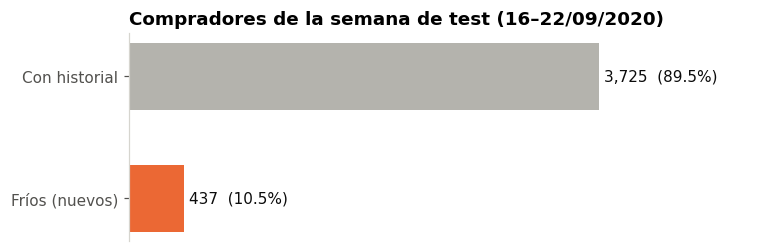

In [5]:
primera_compra = trans.groupby("customer_id")["t_dat"].min()
frios = set(primera_compra[primera_compra >= CORTE].index)

clientes_test = test["customer_id"].nunique()
n_frios = len(frios)
print(f"Clientes que compran en el test: {clientes_test:,}")
print(f"  · con historial: {clientes_test - n_frios:,}")
print(f"  · fríos (nuevos): {n_frios:,}  ->  {n_frios / clientes_test:.1%}")
print(f"Compras por cliente en la semana de test: {len(test) / clientes_test:.1f}")

fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(["Fríos (nuevos)", "Con historial"], [n_frios, clientes_test - n_frios],
        color=[NARANJA, GRIS], height=0.55)
for i, v in enumerate([n_frios, clientes_test - n_frios]):
    ax.text(v + clientes_test * 0.01, i, f"{v:,}  ({v / clientes_test:.1%})", va="center", fontsize=10, color=TEXTO)
ax.set_xlim(0, clientes_test * 1.18)
ax.grid(False); ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Compradores de la semana de test (16–22/09/2020)")
fig.tight_layout()
guardar(fig, "02_clientes_frios")
plt.show()

### 🔎 Interpretación
- En la semana de test compran **4.162 clientes**, y **437 (10,5%) son fríos**: **1 de cada 10 compradores semanales es nuevo**.
- Cada comprador se lleva **~3,9 prendas** en la semana: hay espacio para aumentar productos por pedido con buenas recomendaciones.
- ⚠️ **El 4.162 y el 437 no se "mejoran":** son datos fijos de la realidad (cuántos clientes rinden el examen). Lo que un modelo mejora son las **métricas** (qué porcentaje encuentra algo).

**💼 Implicancia:** cada semana, 1 de cada 10 compradores llega sin historial. Para ellos, un recomendador tradicional no puede personalizar: es el hueco que este proyecto busca cubrir.

**⚙️ Implicancia técnica:** con 437 casos, la métrica en fríos tiene **alta variabilidad** (pocos aciertos más o menos mueven el porcentaje). Más adelante se complementará con **fríos simulados** (punto 6 del EDA).

> **¿Por qué no simulamos fríos todavía?** Los modelos de este notebook (popularidad general y por edad) **no usan el historial del cliente**: recomiendan lo mismo a María y a Lucía si tienen la misma edad. Ocultar historial no cambiaría nada. La simulación cobra sentido con los modelos que sí usan historial (co-compra, ranker).

## 2.3 KPIs y métricas: la vara común del equipo

**Qué hacemos:** traducimos los objetivos de negocio (KPIs) a métricas que se pueden calcular con los datos, programamos esas métricas y las verificamos con casos de resultado conocido. **Todos los modelos del equipo se medirán con estas funciones.**

### Del objetivo de negocio a la métrica
```
Objetivo: que los clientes nuevos encuentren y compren algo desde su primera visita
│
├── KPI principal: CONVERSIÓN de clientes nuevos ──────────► Hit Rate@12 en fríos
├── KPI secundario: PRODUCTOS POR PEDIDO ──────────────────► Recall@12
├── Experiencia / engagement ──────────────────────────────► MAP@12 (principal) · Precision@12
└── Salud del catálogo (no mostrar siempre lo mismo) ──────► Prendas distintas recomendadas
```

### Qué mide cada métrica (ejemplo: le recomendamos 12 prendas a Lucía y compró 3)
| Métrica | Pregunta que responde | Ejemplo con Lucía | Por qué la usamos |
|---|---|---|---|
| **MAP@12** ⭐ | ¿Acertamos **y** pusimos los aciertos arriba? | Si acertamos 1 en el puesto 1 → 1/3 (premia la posición) | Es la **métrica principal**: mide la calidad del ranking y es la oficial de la competencia de H&M (comparable con referencias públicas) |
| **Hit Rate@12** | ¿Compró **al menos 1** de las 12? | Sí → 1 (100%) | **Proxy de conversión:** el KPI principal del negocio, fácil de explicar ("X de cada 100 clientes") |
| **Recall@12** | ¿Qué parte de **lo que compró** estaba en la lista? | 1 de 3 → 33% | **Proxy de productos por pedido:** cuanto más de su compra anticipamos, más fácil sumar prendas al carrito. Es un indicador estándar en recomendación |
| **Precision@12** | ¿Qué parte de **la lista** compró? | 1 de 12 → 8% | Mide el **aprovechamiento de la vitrina**: cada lugar en pantalla es espacio de venta. Es un indicador estándar en recomendación |
| **Prendas distintas recomendadas** | ¿A cuántas prendas diferentes damos visibilidad? | Popularidad general = 12 para todos | Detecta si el sistema **concentra** todo en pocas prendas (riesgo de quiebre de stock y de ignorar la cola larga del EDA) |

### Decisiones y por qué no las alternativas
| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **MAP@12 como métrica principal para elegir** | Combina acierto y orden en un solo número; es estándar en recomendación y en la competencia | **NDCG@12:** mide algo muy similar; sumarla no cambiaría decisiones y complica la comunicación |
| **Hit Rate@12 para comunicar a negocio** | Se traduce directo a "clientes que encontraron algo" | **Solo MAP@12:** sus valores (≈0,008) son difíciles de traducir a negocio |
| **Recall y Precision @12** | Son estándar en recomendación y completan la lectura de negocio | **Accuracy / RMSE / AUC:** son para clasificación o regresión de un valor; no evalúan una **lista corta ordenada** |
| **12 recomendaciones** | Tamaño típico de un carrusel en la web/app y el de la competencia | **5:** poco espacio para explorar · **50:** nadie las ve |
| **Medir aparte a los clientes fríos** | Es el segmento del problema de negocio | **Solo el promedio:** el 90% con historial taparía el resultado del 10% nuevo |
| **Probar las funciones con casos conocidos** | Si la métrica estuviera mal, **todas** las comparaciones serían falsas | **Confiar sin verificar:** un error silencioso invalidaría el proyecto |

> **KPIs que no podemos medir offline:** la **retención** (¿vuelve a comprar?) necesita observar meses después de la recomendación, y la **conversión real** necesita visitas sin compra. Ambas se miden con el **test A/B** del plan de validación cuando H&M implemente el sistema.

In [6]:
K = 12  # prendas recomendadas por cliente

def ap_at_k(reales, predichos, k=K):
    """Average Precision@k de UN cliente: premia acertar y poner los aciertos arriba."""
    aciertos, suma = 0, 0.0
    for i, p in enumerate(predichos[:k]):
        if p in reales:
            aciertos += 1
            suma += aciertos / (i + 1)
    return suma / min(len(reales), k) if reales else 0.0

def detalle_por_cliente(compras, recomendar, k=K):
    """Métricas de cada cliente (sirve para promedios e intervalos de confianza).
    compras: dict cliente -> set de artículos comprados en el período evaluado
    recomendar: función cliente -> lista ordenada de artículos"""
    filas, recomendadas = [], set()
    for cliente, reales in compras.items():
        pred = recomendar(cliente)[:k]
        recomendadas.update(pred)
        aciertos = len(reales & set(pred))
        filas.append((cliente, ap_at_k(reales, pred, k), aciertos > 0, aciertos / k, aciertos / len(reales)))
    det = pd.DataFrame(filas, columns=["customer_id", "ap", "hit", "precision", "recall"])
    return det, len(recomendadas)

def metricas(compras, recomendar, k=K):
    """Todas las métricas del equipo para un grupo de clientes."""
    det, distintas = detalle_por_cliente(compras, recomendar, k)
    return {"MAP@12": det["ap"].mean(), "Hit Rate@12": det["hit"].mean(),
            "Recall@12": det["recall"].mean(), "Precision@12": det["precision"].mean(),
            "Prendas distintas": distintas}

def evaluar(compras, recomendar, k=K):
    """Atajo: (MAP@12, Hit Rate@12), las dos métricas que usamos para decidir."""
    m = metricas(compras, recomendar, k)
    return m["MAP@12"], m["Hit Rate@12"]

def compras_por_cliente(df):
    return df.groupby("customer_id")["article_id"].apply(set).to_dict()

# Pruebas con resultado conocido (Lucía compró la prenda "A")
casos = [({"A"}, ["A", "B", "C"], 1.0),          # acierto en el puesto 1
         ({"A"}, ["B", "C", "D", "A"], 0.25),    # acierto en el puesto 4
         ({"A"}, ["B", "C", "D"], 0.0),          # sin acierto
         ({"A", "B"}, ["A", "X", "B"], (1/1 + 2/3) / 2)]  # dos aciertos
print("MAP: ¿acierta y premia la posición?")
for reales, pred, esperado_ap in casos:
    r = ap_at_k(reales, pred)
    print(f"  reales={reales}, pred={pred} -> {r:.4f}  {'✅' if abs(r - esperado_ap) < 1e-9 else '❌'}")

# Caso Lucía: compró 3 prendas (A, B, C); le recomendamos 12 y acertamos solo A en el puesto 1
lucia = {"lucia": {"A", "B", "C"}}
m = metricas(lucia, lambda c: ["A"] + [f"X{i}" for i in range(11)])
esperado = {"MAP@12": 1 / 3, "Hit Rate@12": 1.0, "Recall@12": 1 / 3, "Precision@12": 1 / 12, "Prendas distintas": 12}
print("Caso Lucía (compró 3, acertamos 1 en el puesto 1):")
for nombre, v in m.items():
    print(f"  {nombre:<18} {v:.4f}  {'✅' if abs(v - esperado[nombre]) < 1e-9 else '❌'}")

MAP: ¿acierta y premia la posición?
  reales={'A'}, pred=['A', 'B', 'C'] -> 1.0000  ✅
  reales={'A'}, pred=['B', 'C', 'D', 'A'] -> 0.2500  ✅
  reales={'A'}, pred=['B', 'C', 'D'] -> 0.0000  ✅
  reales={'A', 'B'}, pred=['A', 'X', 'B'] -> 0.8333  ✅
Caso Lucía (compró 3, acertamos 1 en el puesto 1):
  MAP@12             0.3333  ✅
  Hit Rate@12        1.0000  ✅
  Recall@12          0.3333  ✅
  Precision@12       0.0833  ✅
  Prendas distintas  12.0000  ✅


### 🔎 Interpretación
- Todas las pruebas dan ✅: **las cinco métricas calculan lo que dicen calcular** y pueden usarse para comparar todos los modelos del equipo.
- El MAP@12 **penaliza la posición**: acertar en el puesto 4 vale 4 veces menos que en el puesto 1.
- En el caso de Lucía se ve por qué hacen falta varias métricas: el **Hit Rate es 100%** (encontró algo), pero el **Recall es 33%** (anticipamos 1 de sus 3 compras) y la **Precision 8%** (usamos bien 1 de los 12 lugares). Cada una cuenta una parte distinta de la historia.

**💼 Implicancia:** en un e-commerce el cliente ve primero las prendas de arriba (en el celular, unas 4) y muchos no hacen scroll. **El orden de la recomendación impacta directamente en la conversión**, y la métrica lo refleja.

---
# 3. Baseline: ¿qué puede hacer H&M hoy sin ciencia de datos?

El **baseline** es la estrategia más simple posible: mostrarle a todos los clientes **las 12 prendas más vendidas**. Representa lo que la empresa puede hacer hoy sin modelos. **Si un modelo no supera al baseline, no aporta valor y no justifica su costo.**

## 3.1 ¿Lo más vendido de cuándo? Elección de la ventana en validación

**Pregunta:** ¿conviene mostrar lo más vendido de la última semana, del último mes o de los dos años?

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Comparar 5 ventanas (7, 14, 30, 90 días e histórico)** | Cubre desde "lo de esta semana" hasta "lo de siempre" | **Elegir una a criterio:** sería una suposición sin evidencia |
| **Decidir en la semana de validación** | Es un simulacro dentro del train: el test queda intacto | **Decidir en el test:** sobreestima el resultado (*leakage* de decisión) |
| **Criterio: mayor MAP@12** | Es la métrica principal, **definida antes** de ver los resultados | **Cambiar de criterio después de ver los números:** sería acomodar la conclusión |

In [7]:
def top_k(df, hasta, dias=None, k=K):
    """Las k prendas más vendidas antes de 'hasta' (dias=None -> todo el historial)."""
    d = df[df["t_dat"] < hasta]
    if dias is not None:
        d = d[d["t_dat"] >= hasta - pd.Timedelta(days=dias)]
    return d["article_id"].value_counts().head(k).index.tolist()

val_compras = compras_por_cliente(train[train["t_dat"] >= VAL])
print(f"Clientes en la semana de validación: {len(val_compras):,}")

filas = []
for dias in [7, 14, 30, 90, None]:
    top = top_k(train, VAL, dias)
    m, h = evaluar(val_compras, lambda c, t=top: t)
    filas.append({"Ventana": f"{dias} días" if dias else "Histórico", "dias": dias, "MAP@12": m, "Hit Rate@12": h})
validacion_baseline = pd.DataFrame(filas)

ganadora = validacion_baseline.loc[validacion_baseline["MAP@12"].idxmax()]
VENTANA = None if pd.isna(ganadora["dias"]) else int(ganadora["dias"])   # None = histórico
ETIQUETA_VENTANA = ganadora["Ventana"]
print(f"Ventana ganadora en validación: {ETIQUETA_VENTANA}")

tabla = validacion_baseline.drop(columns="dias")
tabla.assign(**{"MAP@12": tabla["MAP@12"].round(4), "Hit Rate@12": (tabla["Hit Rate@12"] * 100).round(2)}).rename(columns={"Hit Rate@12": "Hit Rate@12 (%)"})

Clientes en la semana de validación: 4,356
Ventana ganadora en validación: 7 días


,Ventana,MAP@12,Hit Rate@12 (%)
0,7 días,0.0073,6.13
1,14 días,0.0059,6.04
2,30 días,0.0057,6.75
3,90 días,0.0044,4.02
4,Histórico,0.0048,3.49


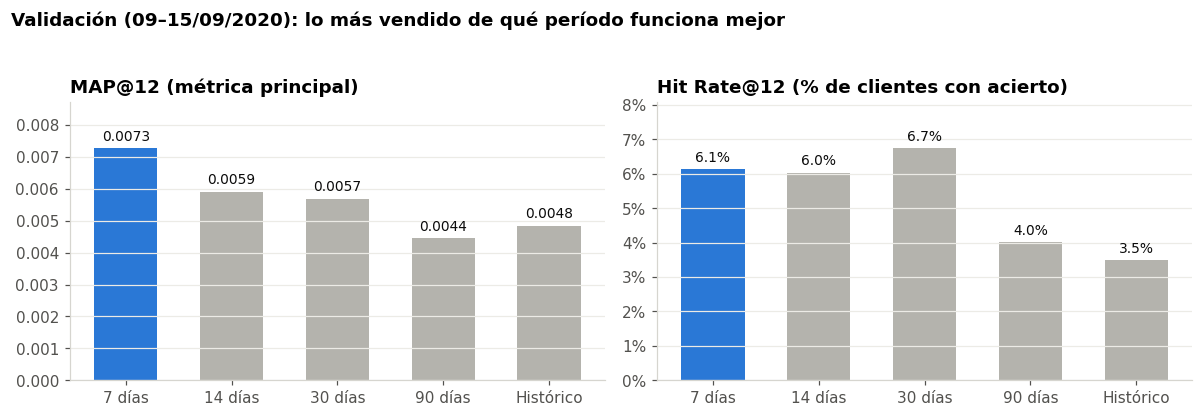

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
colores = [AZUL if v == ETIQUETA_VENTANA else GRIS for v in validacion_baseline["Ventana"]]
for ax, col, fmt, titulo in [(axes[0], "MAP@12", lambda v: f"{v:.4f}", "MAP@12 (métrica principal)"),
                             (axes[1], "Hit Rate@12", lambda v: f"{v:.1%}", "Hit Rate@12 (% de clientes con acierto)")]:
    barras = ax.bar(validacion_baseline["Ventana"], validacion_baseline[col], color=colores, width=0.6)
    rotular_barras(ax, barras, fmt)
    ax.set_title(titulo)
    ax.set_ylim(0, validacion_baseline[col].max() * 1.2)
    if col == "Hit Rate@12":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Validación (09–15/09/2020): lo más vendido de qué período funciona mejor", x=0.01, ha="left",
             fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
guardar(fig, "03_validacion_ventanas")
plt.show()

### 🔎 Interpretación
| Ventana | MAP@12 | Hit Rate@12 |
|---|---|---|
| **7 días** | **0,0073** | 6,13% |
| 14 días | 0,0059 | 6,04% |
| 30 días | 0,0057 | 6,75% |
| 90 días | 0,0044 | 4,02% |
| Histórico | 0,0048 | 3,49% |

1. **Lo reciente gana:** la popularidad de los últimos 7 días supera al histórico en **+52% de MAP@12** y casi duplica el Hit Rate (6,1% vs 3,5%). Confirma con métricas la **estacionalidad** del EDA.
2. **Balance cobertura / orden:** 30 días llega a más clientes (mayor Hit Rate), pero **7 días ordena mejor**. Se elige **7 días** porque MAP@12 es la métrica principal definida antes de ver los resultados.
3. ⚠️ **Limitación:** con ~4.400 clientes, diferencias pequeñas entre ventanas cercanas (14 vs 30 días) pueden ser azar. La diferencia **reciente vs histórico** es grande y consistente.

**💼 Implicancia:** la moda tiene "fecha de vencimiento". Lo que más se vendió en dos años incluye otras temporadas y colecciones; **lo de la última semana refleja lo que la gente quiere ahora**.

## 3.2 Resultado del baseline en el test (el examen real)

**Qué hacemos:** con la ventana elegida, medimos en la semana de test los dos baselines (histórico y reciente) para **todos** los clientes y para los **fríos**. Además, un **escenario de diagnóstico** sin prendas nuevas (punto 7 del EDA).

**Cómo se lee:** las 12 prendas se calculan **solo con el train** (la reciente, con la última semana: 09–15/09) y se comparan con lo que cada cliente **compró realmente** en el test.

> **Escenario "sin artículos nuevos":** algunos clientes compraron prendas que **no existían antes del corte**; ningún modelo basado en historial puede recomendarlas. Este escenario las quita para **medir cuánto nos afectan**. **No es el resultado oficial**: en la realidad esas compras ocurren.

In [9]:
top_hist = top_k(train, CORTE, None)
top_rec  = top_k(train, CORTE, VENTANA)

test_compras = compras_por_cliente(test)
test_frios   = {c: a for c, a in test_compras.items() if c in frios}
art_train    = set(train["article_id"])
test_sin_nuevos = {c: a & art_train for c, a in test_compras.items() if a & art_train}

def fila(modelo, grupo, compras, rec):
    return {"Modelo": modelo, "Grupo": grupo, "Clientes": len(compras), **metricas(compras, rec)}

def tabla_bonita(df):
    out = df.copy()
    out["MAP@12"] = out["MAP@12"].round(4)
    for col in ["Hit Rate@12", "Recall@12", "Precision@12"]:
        if col in out:
            out[col + " (%)"] = (out.pop(col) * 100).round(2)
    return out

NOMBRE_HIST = "Baseline histórico"
NOMBRE_REC  = f"Baseline reciente ({ETIQUETA_VENTANA})"
filas = []
for nombre, top in [(NOMBRE_HIST, top_hist), (NOMBRE_REC, top_rec)]:
    for grupo, compras in [("Todos", test_compras), ("Fríos", test_frios), ("Sin artículos nuevos*", test_sin_nuevos)]:
        filas.append(fila(nombre, grupo, compras, lambda c, t=top: t))
resultados_baseline = pd.DataFrame(filas)

solo_nuevos = len(test_compras) - len(test_sin_nuevos)
print(f"Clientes que compraron SOLO prendas nuevas: {solo_nuevos} ({solo_nuevos / len(test_compras):.1%})")
tabla_bonita(resultados_baseline)

Clientes que compraron SOLO prendas nuevas: 153 (3.7%)


,Modelo,Grupo,Clientes,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Baseline histórico,Todos,4162,0.0029,12,2.45,0.73,0.23
1,Baseline histórico,Fríos,437,0.0009,12,1.83,0.42,0.17
2,Baseline histórico,Sin artículos nuevos*,4009,0.0031,12,2.54,0.80,0.24
3,Baseline reciente (7 días),Todos,4162,0.0083,12,6.97,2.71,0.65
4,Baseline reciente (7 días),Fríos,437,0.0072,12,4.58,2.07,0.46
5,Baseline reciente (7 días),Sin artículos nuevos*,4009,0.0089,12,7.23,2.98,0.68


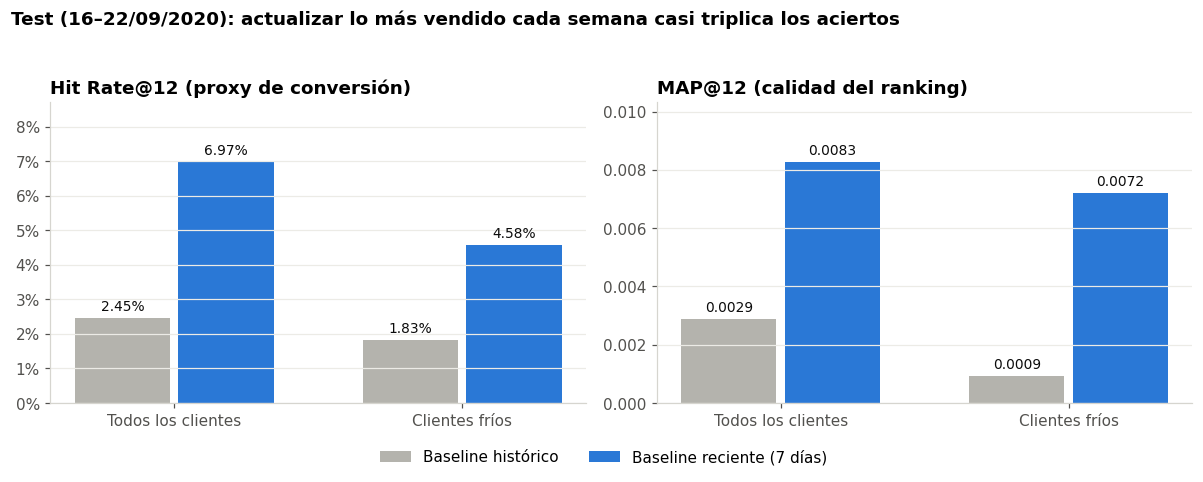

In [10]:
datos = resultados_baseline[resultados_baseline["Grupo"].isin(["Todos", "Fríos"])]
grupos = ["Todos", "Fríos"]
x = np.arange(len(grupos)); w = 0.36

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, fmt, titulo in [(axes[0], "Hit Rate@12", lambda v: f"{v:.2%}", "Hit Rate@12 (proxy de conversión)"),
                             (axes[1], "MAP@12", lambda v: f"{v:.4f}", "MAP@12 (calidad del ranking)")]:
    for j, (nombre, color) in enumerate([(NOMBRE_HIST, GRIS), (NOMBRE_REC, AZUL)]):
        vals = [datos[(datos["Modelo"] == nombre) & (datos["Grupo"] == g)][col].iloc[0] for g in grupos]
        barras = ax.bar(x + (j - 0.5) * w, vals, w * 0.92, color=color, label=nombre)
        rotular_barras(ax, barras, fmt)
    ax.set_xticks(x, ["Todos los clientes", "Clientes fríos"])
    ax.set_title(titulo)
    ax.set_ylim(0, datos[col].max() * 1.25)
    if col == "Hit Rate@12":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Test (16–22/09/2020): actualizar lo más vendido cada semana casi triplica los aciertos",
             x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
guardar(fig, "04_baseline_test")
plt.show()

### 🔎 Interpretación
| Baseline | Grupo | Clientes | MAP@12 | Hit Rate@12 |
|---|---|---|---|---|
| Histórico | Todos | 4.162 | 0,0029 | 2,45% |
| Histórico | Fríos | 437 | 0,0009 | 1,83% |
| **Reciente (7 días)** | **Todos** | 4.162 | **0,0083** | **6,97%** |
| **Reciente (7 días)** | **Fríos** | 437 | **0,0072** | **4,58%** |
| Reciente (7 días) | Sin artículos nuevos* | 4.009 | 0,0089 | 7,23% |

**Hallazgo 1. La popularidad reciente es ~3 veces mejor que la histórica.** Las 12 prendas más vendidas de la última semana le sirven al 6,97% de los clientes (~290), contra el 2,45% (~102) con las más vendidas de dos años. La ventaja aparece en validación (+52%) **y** en test (~3x): la decisión es **robusta**, no fue suerte.

**Hallazgo 2. Los clientes fríos son más difíciles.** Con el mejor baseline, aciertan el **4,58%** frente al **6,97%** del total. Lo más vendido representa peor los gustos de alguien nuevo. **Esto justifica un modelo específico para clientes nuevos.** Con 437 casos (~20 aciertos) la cifra es inestable.

**Hallazgo 3. Las prendas nuevas son un techo (punto 7).** **153 clientes (3,7%)** compraron solo prendas que no existían antes del corte: ningún modelo basado en historial puede acertarles. Quitarlas sube el MAP@12 un **7%** (0,0083 → 0,0089). Para cubrirlas hará falta un **modelo de contenido** que use atributos de la prenda (tipo, color, sección).

**Lectura de las otras métricas (ver tabla):**
- **Recall@12** (proxy de productos por pedido): muestra qué parte de lo que compran anticipamos. Con una lista igual para todos es baja: cada cliente compra en promedio ~4 prendas distintas y casi ninguna es "lo más vendido".
- **Precision@12** (aprovechamiento de la vitrina): es muy baja en todos los casos porque de 12 lugares se acierta, como mucho, 1. Es normal en recomendación con más de 100.000 prendas.
- **Prendas distintas = 12:** la popularidad muestra **las mismas 12 prendas a todos**. Para el negocio, concentra la visibilidad en muy pocos productos (riesgo de quiebre de stock) y deja invisible la **cola larga** del EDA.

### 🎯 Baseline oficial del equipo
> **Popularidad de los últimos 7 días → MAP@12 = 0,0083 · Hit Rate@12 = 6,97% (todos) · 4,58% (fríos).**

### 💼 Traducción para el negocio
- **Hoy:** mostrando las 12 prendas más vendidas de la semana, **7 de cada 100 clientes** encuentran algo que compran; entre los **nuevos, solo 4 o 5 de cada 100**.
- **Más del 95% de los clientes nuevos no encuentra nada relevante** en las recomendaciones: es conversión que hoy se pierde.
- **Primera recomendación sin costo:** actualizar "lo más vendido" **cada semana** en lugar de usar el histórico **casi triplica** los clientes que encuentran algo (de 2 a 7 de cada 100).

---
# 4. Modelo 1: popularidad por tramo de edad (Hipótesis H1)

> **H1:** *Recomendar las prendas más vendidas **entre clientes de la misma edad** supera al baseline general en clientes nuevos.*

### ¿Por qué este modelo primero?
- **El problema:** un cliente nuevo no tiene historial; no podemos personalizar por lo que compró.
- **La oportunidad:** la **edad** se informa al registrarse → está disponible **desde la primera visita**.
- **La evidencia del EDA:** la edad es **bimodal** (grupos de ~20–30 y ~50 años) y **cambia la mezcla de productos**. Si los gustos cambian con la edad, una sola lista para todos no representa a nadie en particular.

### ¿Por qué importa para la empresa?
- **Personalización desde la primera visita**, sin esperar a que el cliente compre.
- **Simple, barata y explicable:** es un conteo que se actualiza cada semana; cualquier gerente entiende por qué se recomienda cada prenda.
- Si funciona, es **implementable de inmediato**, antes de modelos más complejos.

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Usar solo la edad** | Está disponible al registrarse y el EDA muestra que cambia los gustos | **FN, Active, club_member_status, fashion_news_frequency:** son una foto de un solo momento (riesgo de *leakage*) y aportan poca señal (decisión 5) |
| | | **postal_code:** 87.652 códigos para 110.252 clientes; el 82% tiene un solo cliente: no generaliza |
| **5 tramos (<25, 25–34, 35–44, 45–54, 55+)** | Separan los dos grupos que muestra el EDA y dejan suficientes compras por tramo | **Tramos de 5 años:** listas con muy pocas compras, ruidosas · **2 tramos:** pierde diferencias |
| **"Sin edad" como grupo propio** | No se inventan datos (decisión 4) y su lista refleja lo que compran | **Imputar con la mediana:** asignaría gustos de 31 años a gente de cualquier edad |
| **Completar con el top general** | Si un tramo tiene menos de 12 prendas, el cliente igual recibe 12 | **Dejar la lista incompleta:** recomendación más pobre sin necesidad |
| **Datos reales (sin datos sintéticos)** | Hay 2,2 millones de compras reales: alcanzan | **Datos sintéticos:** se usan cuando faltan datos; acá restarían credibilidad |

## 4.1 Evidencia: ¿la edad cambia lo que se compra?
**Qué hacemos:** creamos los tramos y medimos, en el train, qué porcentaje de las compras de cada tramo va a cada grupo de productos (`index_group_name`).

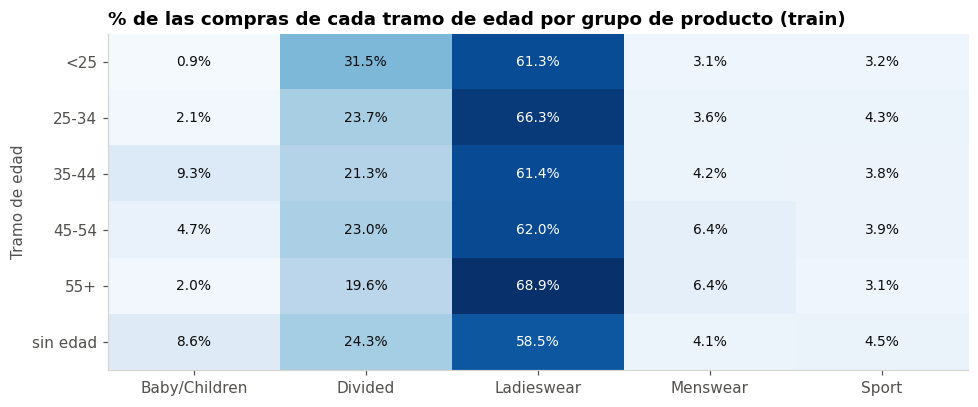

In [11]:
bins   = [0, 25, 35, 45, 55, 120]
TRAMOS = ["<25", "25-34", "35-44", "45-54", "55+"]
cust["tramo_edad"] = pd.cut(cust["age"], bins=bins, labels=TRAMOS, right=False).astype(str)
cust.loc[cust["age"].isna(), "tramo_edad"] = "sin edad"   # decisión 4: no imputamos
tramo = cust.set_index("customer_id")["tramo_edad"].to_dict()
ORDEN = TRAMOS + ["sin edad"]

# Mezcla de productos por tramo (solo train: no miramos el test)
mezcla = (train[["customer_id", "article_id"]]
          .assign(tramo=lambda d: d["customer_id"].map(tramo))
          .merge(art[["article_id", "index_group_name"]], on="article_id"))
mezcla = pd.crosstab(mezcla["tramo"], mezcla["index_group_name"], normalize="index").reindex(ORDEN) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(mezcla.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(mezcla.shape[1]), mezcla.columns, rotation=0)
ax.set_yticks(range(mezcla.shape[0]), mezcla.index)
for i in range(mezcla.shape[0]):
    for j in range(mezcla.shape[1]):
        v = mezcla.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
                color="white" if v > mezcla.values.max() * 0.6 else TEXTO)
ax.grid(False)
ax.set_title("% de las compras de cada tramo de edad por grupo de producto (train)")
ax.set_ylabel("Tramo de edad")
fig.tight_layout()
guardar(fig, "05_mezcla_por_edad")
plt.show()

### 🔎 Cómo leer el mapa de calor
Cada fila suma 100%: muestra **en qué gastan** los clientes de ese tramo. Si las filas fueran iguales, la edad no aportaría nada; **si cambian, cada tramo necesita su propia lista**. Fijate especialmente en la columna **Divided** (línea juvenil): el EDA documentó que su peso **cae a casi la mitad** entre los más jóvenes y los mayores.

**💼 Implicancia:** mostrarle a una clienta de 55 años lo mismo que a una de 20 desperdicia los lugares más visibles de la página en prendas que probablemente no le interesen.

## 4.2 ¿Cuántos clientes deja cada tramo? (punto 8 del EDA)
**Por qué importa:** cada tramo necesita suficientes compras para que su "top 12" sea confiable, y queremos saber cómo se reparten los clientes nuevos.

In [12]:
resumen_tramos = pd.DataFrame({
    "Clientes": cust["tramo_edad"].value_counts(),
    "Compras en la última semana del train": train[train["t_dat"] >= VAL]["customer_id"].map(tramo).value_counts(),
    "Fríos en el test": pd.Series([tramo.get(c, "sin edad") for c in frios]).value_counts(),
}).reindex(ORDEN).fillna(0).astype(int)
resumen_tramos["% clientes"] = (resumen_tramos["Clientes"] / resumen_tramos["Clientes"].sum() * 100).round(1)
resumen_tramos

,Clientes,Compras en la última semana del train,Fríos en el test,% clientes
<25,29312,4318,150,26.6
25-34,32915,6428,115,29.9
35-44,13323,1915,40,12.1
45-54,19675,2945,82,17.8
55+,13819,1858,50,12.5
sin edad,1208,55,0,1.1


### 🔎 Cómo leer la tabla
- **Compras en la última semana del train:** es la "materia prima" de cada lista. Si un tramo tiene pocas compras, su top 12 es más inestable y conviene una ventana más larga (lo decide la validación en 4.3).
- **Fríos en el test:** muestra a qué tramos pertenecen los clientes nuevos. Si se concentran en tramos jóvenes, el modelo por edad tiene más oportunidad de diferenciarse del top general.
- El grupo **"sin edad"** es muy chico: su resultado casi no mueve el promedio, coherente con la decisión de no imputar.

## 4.3 Construcción del modelo y elección de ventana (validación)
**Qué hacemos:** para cada tramo calculamos las 12 prendas más vendidas de los últimos *N* días; a cada cliente le recomendamos la lista de su tramo (completando con el top general si hace falta). Probamos 7, 14 y 30 días **en validación**.

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Volver a elegir la ventana** | Al dividir en tramos, cada lista tiene **menos compras**: la ventana óptima puede ser más larga que la del baseline | **Reusar 7 días sin probar:** podría dejar tramos con muy pocos datos |
| **Elección automática por MAP@12** | El código toma la ganadora: nadie la elige mirando el test | **Elegir a mano:** abre la puerta a sesgos |

In [13]:
def top_por_tramo(df, hasta, dias, k=K):
    """Las k prendas más vendidas de cada tramo en los últimos 'dias' antes de 'hasta'."""
    d = df[(df["t_dat"] < hasta) & (df["t_dat"] >= hasta - pd.Timedelta(days=dias))]
    d = d.assign(tramo=d["customer_id"].map(tramo))
    conteo = d.groupby("tramo")["article_id"].value_counts()
    return {t: s.sort_values(ascending=False).head(k).index.get_level_values("article_id").tolist()
            for t, s in conteo.groupby(level=0)}

def recomendar_por_tramo(tops, top_general):
    """Lista del tramo del cliente; si le faltan prendas, completa con el top general."""
    def rec(cliente):
        lista = tops.get(tramo.get(cliente, "sin edad"), [])
        return (lista + [a for a in top_general if a not in lista])[:K]
    return rec

filas = []
for dias in [7, 14, 30]:
    rec = recomendar_por_tramo(top_por_tramo(train, VAL, dias), top_k(train, VAL, dias))
    m, h = evaluar(val_compras, rec)
    filas.append({"Ventana": f"{dias} días", "MAP@12": m, "Hit Rate@12": h})
validacion_edad = pd.DataFrame(filas)

VENTANA_TRAMO = int(validacion_edad.loc[validacion_edad["MAP@12"].idxmax(), "Ventana"].split()[0])
print(f"Ventana ganadora en validación para el modelo por edad: {VENTANA_TRAMO} días")
tabla_bonita(validacion_edad)

Ventana ganadora en validación para el modelo por edad: 30 días


,Ventana,MAP@12,Hit Rate@12 (%)
0,7 días,0.0074,5.79
1,14 días,0.0072,6.11
2,30 días,0.0080,6.29


### 🔎 Cómo leer
La ventana con mayor MAP@12 en el simulacro es la que se usa en el test. Si gana una **más larga** que la del baseline, confirma que dividir por tramos reduce los datos por lista y hace falta mirar más días para que sea estable.

## 4.4 Evaluación en el test: ¿se cumple H1?

**Criterio de éxito (definido ANTES de ver los resultados):** H1 se cumple si el modelo por edad **supera al baseline oficial en los clientes fríos** en **MAP@12** (métrica principal) y en **Hit Rate@12** (proxy de conversión).

> Escribir el criterio antes de correr el modelo demuestra que la conclusión no se acomodó a los números.

In [14]:
modelo_edad = recomendar_por_tramo(top_por_tramo(train, CORTE, VENTANA_TRAMO), top_rec)
NOMBRE_M1 = f"Modelo 1: popularidad por edad ({VENTANA_TRAMO} días)"

filas = []
for nombre, rec in [(NOMBRE_REC, lambda c: top_rec), (NOMBRE_M1, modelo_edad)]:
    for grupo, compras in [("Todos", test_compras), ("Fríos", test_frios)]:
        filas.append(fila(nombre, grupo, compras, rec))
comparacion_h1 = pd.DataFrame(filas)
tabla_bonita(comparacion_h1)

,Modelo,Grupo,Clientes,MAP@12,Prendas distintas,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Baseline reciente (7 días),Todos,4162,0.0083,12,6.97,2.71,0.65
1,Baseline reciente (7 días),Fríos,437,0.0072,12,4.58,2.07,0.46
2,Modelo 1: popularidad por edad (30 días),Todos,4162,0.0056,54,5.43,2.06,0.48
3,Modelo 1: popularidad por edad (30 días),Fríos,437,0.0058,44,4.35,1.86,0.38


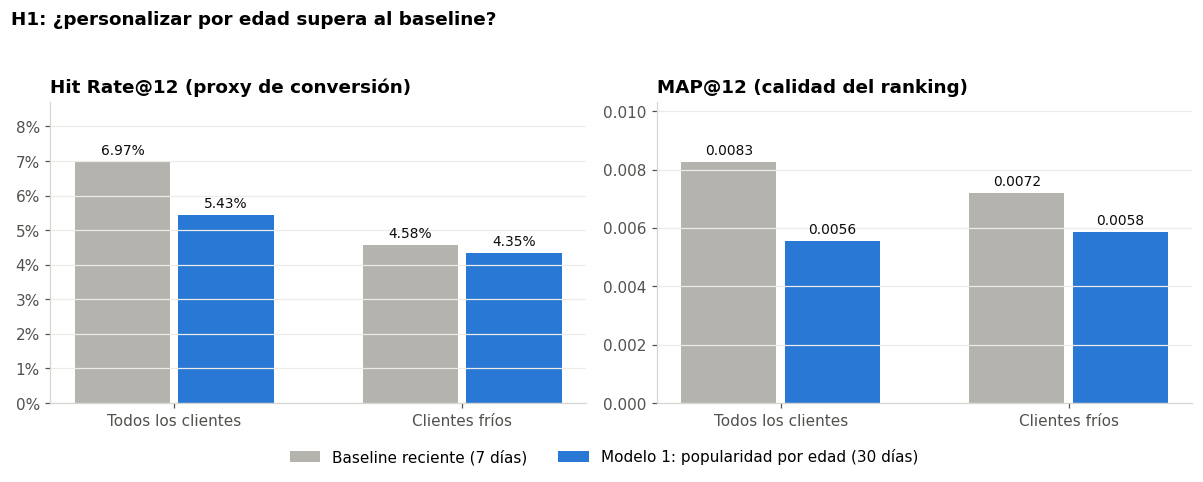

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, fmt, titulo in [(axes[0], "Hit Rate@12", lambda v: f"{v:.2%}", "Hit Rate@12 (proxy de conversión)"),
                             (axes[1], "MAP@12", lambda v: f"{v:.4f}", "MAP@12 (calidad del ranking)")]:
    for j, (nombre, color) in enumerate([(NOMBRE_REC, GRIS), (NOMBRE_M1, AZUL)]):
        vals = [comparacion_h1[(comparacion_h1["Modelo"] == nombre) & (comparacion_h1["Grupo"] == g)][col].iloc[0]
                for g in grupos]
        barras = ax.bar(x + (j - 0.5) * w, vals, w * 0.92, color=color, label=nombre)
        rotular_barras(ax, barras, fmt)
    ax.set_xticks(x, ["Todos los clientes", "Clientes fríos"])
    ax.set_title(titulo)
    ax.set_ylim(0, comparacion_h1[col].max() * 1.25)
    if col == "Hit Rate@12":
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("H1: ¿personalizar por edad supera al baseline?", x=0.01, ha="left", fontweight="bold", fontsize=12, y=1.04)
fig.tight_layout()
guardar(fig, "06_h1_edad_vs_baseline")
plt.show()

In [16]:
# Veredicto automático de H1 (aplica el criterio definido antes de ver los resultados)
def valor(modelo, grupo, col):
    return comparacion_h1[(comparacion_h1["Modelo"] == modelo) & (comparacion_h1["Grupo"] == grupo)][col].iloc[0]

b_map, b_hit = valor(NOMBRE_REC, "Fríos", "MAP@12"), valor(NOMBRE_REC, "Fríos", "Hit Rate@12")
m_map, m_hit = valor(NOMBRE_M1, "Fríos", "MAP@12"), valor(NOMBRE_M1, "Fríos", "Hit Rate@12")
d_map, d_hit = (m_map / b_map - 1) if b_map else float("nan"), m_hit - b_hit
nuevos_extra = d_hit * len(test_frios)

print("VEREDICTO H1 — clientes fríos")
print(f"  MAP@12:      baseline {b_map:.4f} -> modelo {m_map:.4f}  ({d_map:+.0%})")
print(f"  Hit Rate@12: baseline {b_hit:.2%} -> modelo {m_hit:.2%}  ({d_hit * 100:+.2f} puntos)")
print()
if m_map > b_map and m_hit > b_hit:
    print("✅ H1 SE CUMPLE: personalizar por edad mejora las recomendaciones para clientes nuevos.")
    print(f"   En la semana de test, ~{nuevos_extra:.0f} clientes nuevos más (de {len(test_frios)}) "
          f"habrían encontrado una prenda que terminaron comprando.")
    print(f"   Por cada 100 clientes nuevos: {b_hit * 100:.1f} -> {m_hit * 100:.1f} encuentran algo.")
elif m_map > b_map or m_hit > b_hit:
    print("🟡 H1 SE CUMPLE PARCIALMENTE: el modelo mejora una métrica pero no la otra.")
    print("   La edad aporta señal, pero sola no alcanza: conviene combinarla con atributos de producto o co-compra.")
else:
    print("❌ H1 NO SE CUMPLE: la edad sola no supera a lo más vendido de la semana.")
    print("   Es un resultado válido: indica que hace falta más información (atributos de producto, co-compra)")
    print("   y justifica los modelos más complejos de la siguiente fase.")
print()
print(f"⚠️ Con {len(test_frios)} clientes fríos, diferencias de pocos aciertos pueden deberse al azar;")
print("   se confirmará con fríos simulados cuando se agreguen modelos que usan historial.")

VEREDICTO H1 — clientes fríos
  MAP@12:      baseline 0.0072 -> modelo 0.0058  (-19%)
  Hit Rate@12: baseline 4.58% -> modelo 4.35%  (-0.23 puntos)

❌ H1 NO SE CUMPLE: la edad sola no supera a lo más vendido de la semana.
   Es un resultado válido: indica que hace falta más información (atributos de producto, co-compra)
   y justifica los modelos más complejos de la siguiente fase.

⚠️ Con 437 clientes fríos, diferencias de pocos aciertos pueden deberse al azar;
   se confirmará con fríos simulados cuando se agreguen modelos que usan historial.


### 🔎 Interpretación y 💼 implicancias
El veredicto de arriba aplica el criterio definido de antemano. Cómo comunicarlo según el resultado:

- **Si H1 se cumple ✅:** *"Personalizar por edad permite que más clientes nuevos encuentren algo en su primera visita, con un modelo simple, barato y explicable. Es la primera recomendación implementable y la nueva vara para los modelos de la siguiente fase."*
- **Si se cumple parcialmente 🟡 o no se cumple ❌:** *"La edad sola no alcanza para diferenciar los gustos de un cliente nuevo frente a lo más vendido de la semana. Esto justifica incorporar atributos de producto y patrones de co-compra."* En ciencia de datos, **una hipótesis rechazada también es un hallazgo**: evita invertir en una solución que no funciona.

**Implicancia técnica:** el resultado en **todos los clientes** muestra si personalizar por edad también ayuda a quienes tienen historial, o si para ellos conviene usar su historial (co-compra, ranker).

## 4.5 ¿La diferencia es real o es azar? Intervalo de confianza

**Por qué:** con 437 clientes fríos, unos pocos aciertos de más o de menos cambian el porcentaje. Un evaluador crítico preguntará *"¿esa mejora no es casualidad?"*.

**Qué hacemos:** un **bootstrap**: re-sorteamos 1.000 veces a los clientes fríos (con reposición), recalculamos la diferencia entre el modelo y el baseline, y vemos en qué rango cae el 95% de las veces.

| Decisión | ✅ Por qué sí | ❌ Por qué no la alternativa |
|---|---|---|
| **Bootstrap** | No supone ninguna distribución y es fácil de explicar ("repetimos el examen 1.000 veces con otros alumnos") | **Test t:** supone normalidad, y las métricas por cliente son casi siempre 0 (no normales) |
| **Comparación pareada** (mismos clientes en cada sorteo) | Elimina la variación por "qué clientes tocaron" y aísla el efecto del modelo | **Intervalos separados por modelo:** se superponen fácilmente y subestiman la evidencia |

In [17]:
rng = np.random.default_rng(42)   # semilla fija: el resultado es reproducible
det_base, _ = detalle_por_cliente(test_frios, lambda c: top_rec)
det_mod, _  = detalle_por_cliente(test_frios, modelo_edad)
d_ap  = (det_mod["ap"].values - det_base["ap"].values)
d_hit = (det_mod["hit"].values.astype(float) - det_base["hit"].values.astype(float))

idx = rng.integers(0, len(d_ap), size=(1000, len(d_ap)))
boot_map, boot_hit = d_ap[idx].mean(axis=1), d_hit[idx].mean(axis=1)

for nombre, obs, boot, fmt in [("MAP@12", d_ap.mean(), boot_map, "{:+.4f}"),
                               ("Hit Rate@12", d_hit.mean(), boot_hit, "{:+.2%}")]:
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"Diferencia {nombre} (modelo - baseline) en fríos: {fmt.format(obs)}  "
          f"IC 95%: [{fmt.format(lo)}, {fmt.format(hi)}]  ->  "
          + ("diferencia ROBUSTA ✅" if lo > 0 or hi < 0 else f"el intervalo incluye 0: no concluyente con {len(test_frios)} clientes 🟡"))
print(f"Clientes nuevos con acierto: baseline {int(det_base['hit'].sum())} · modelo {int(det_mod['hit'].sum())} (de {len(test_frios)})")

Diferencia MAP@12 (modelo - baseline) en fríos: -0.0014  IC 95%: [-0.0109, +0.0064]  ->  el intervalo incluye 0: no concluyente con 437 clientes 🟡
Diferencia Hit Rate@12 (modelo - baseline) en fríos: -0.23%  IC 95%: [-2.52%, +2.07%]  ->  el intervalo incluye 0: no concluyente con 437 clientes 🟡
Clientes nuevos con acierto: baseline 20 · modelo 19 (de 437)


### 🔎 Cómo leerlo
- **Si el intervalo no incluye el 0** → la mejora (o empeora) es **robusta**: se mantiene aunque cambien los clientes evaluados.
- **Si incluye el 0** → con 437 clientes **no alcanza para afirmarlo**. No significa que el modelo no sirva, sino que hacen falta más casos: por eso el plan incluye **fríos simulados** y evaluar en más semanas.

**💼 Implicancia:** este análisis evita prometer a la dirección una mejora que podría ser casualidad: es parte de un **análisis crítico de resultados**.

## 4.6 Ejemplos reales: ¿qué ve un cliente nuevo?

**Por qué:** las métricas resumen miles de casos, pero un ejemplo concreto se entiende mejor. Los ejemplos sirven para mostrar que el sistema es **coherente**.

**Qué hacemos:** tomamos una clienta nueva joven y otra mayor (de la semana de test) y mostramos sus 12 recomendaciones con ambos enfoques, marcando con ✅ lo que realmente compraron.

In [18]:
cols_art = [c for c in ["prod_name", "product_type_name", "colour_group_name", "index_group_name"] if c in art.columns]
info_art = art.set_index("article_id")[cols_art]

def ver_recomendacion(cliente):
    compro = test_compras.get(cliente, set())
    tabla = pd.DataFrame({"Puesto": range(1, K + 1),
                          "Baseline (lo más vendido)": top_rec[:K],
                          "Modelo 1 (por edad)": modelo_edad(cliente)[:K]})
    for col in ["Baseline (lo más vendido)", "Modelo 1 (por edad)"]:
        nombres = tabla[col].map(lambda a: " · ".join(str(info_art.loc[a, c]) for c in cols_art[:2]) if a in info_art.index else str(a))
        tabla[col] = [("✅ " if a in compro else "") + n for a, n in zip(tabla[col], nombres)]
    return tabla

frios_con_edad = cust[cust["customer_id"].isin(frios)].dropna(subset=["age"]).sort_values("customer_id")
ejemplos = [frios_con_edad[frios_con_edad["age"] < 25].head(1), frios_con_edad[frios_con_edad["age"] >= 45].head(1)]
for ej in ejemplos:
    if len(ej):
        c = ej["customer_id"].iloc[0]
        print(f"\nCliente nueva · {int(ej['age'].iloc[0])} años · tramo {tramo[c]} · compró {len(test_compras.get(c, []))} prendas distintas en el test")
        display(ver_recomendacion(c))


Cliente nueva · 22 años · tramo <25 · compró 1 prendas distintas en el test


,Puesto,Baseline (lo más vendido),Modelo 1 (por edad)
0,1,FF PI Haley dress · Dress,Nika vest · Sweater
1,2,Pink HW barrel · Trousers,Perrie Slim Mom Denim TRS · Trousers
2,3,Atomic Wrap Sweater · Sweater,Bailey · Cardigan
3,4,Perrie Slim Mom Denim TRS · Trousers,Pluto RW slacks (1) · Trousers
4,5,Hilton · Cardigan,Jade HW Skinny Denim TRS · Trousers
5,6,Matey · Sweater,Rose thong 7-pack(1) · Underwear bottom
6,7,Pluto RW slacks (1) · Trousers,Becka hoodie · Hoodie
7,8,Ohlsson · Sweater,Mariah fancy dobby · Dress
8,9,Atomic Wrap Sweater · Sweater,Jennifer · Blazer
9,10,Jackie cable vest · Sweater,STRONG HW seamless tights · Leggings/Tights



Cliente nueva · 51 años · tramo 45-54 · compró 2 prendas distintas en el test


,Puesto,Baseline (lo más vendido),Modelo 1 (por edad)
0,1,FF PI Haley dress · Dress,Pluto RW slacks (1) · Trousers
1,2,Pink HW barrel · Trousers,Pluto RW slacks (1) · Trousers
2,3,Atomic Wrap Sweater · Sweater,PETAR SWEATSHIRT · Sweater
3,4,Perrie Slim Mom Denim TRS · Trousers,Liliana · Sweater
4,5,Hilton · Cardigan,Jade HW Skinny Denim TRS · Trousers
5,6,Matey · Sweater,Lucy blouse · Shirt
6,7,Pluto RW slacks (1) · Trousers,Perrie Slim Mom Denim TRS · Trousers
7,8,Ohlsson · Sweater,Lucien CONSCIOUS · Blouse
8,9,Atomic Wrap Sweater · Sweater,Mariette Blazer · Blazer
9,10,Jackie cable vest · Sweater,Primo slacks · Trousers


### 🔎 Cómo leerlo
- La columna **Baseline** es **idéntica para todas las clientas**, sin importar su edad.
- La columna **Modelo 1** cambia según el tramo: es lo que permite que una clienta de 20 y otra de 50 vean vitrinas distintas.
- Los ✅ marcan las prendas que **compró de verdad** en la semana de test. Que no haya ✅ en un ejemplo es normal: el Hit Rate es de ~5%.

**💼 Implicancia:** permite explicar el sistema en lenguaje de negocio: *"esta clienta de 20 años vio esto; esta de 55 vio esto otro"*.

## 4.7 Trade-offs: qué ganamos y qué resignamos

| Enfoque | ✅ Ventajas | ⚠️ Desventajas | ¿Cuándo usarlo? |
|---|---|---|---|
| **Popularidad histórica** | Trivial de calcular | Ignora la temporada: el peor resultado | Nunca como estrategia principal |
| **Popularidad reciente (7 días)** | Simple, barata, capta tendencias | Igual para todos; solo 12 prendas visibles; no puede recomendar prendas nuevas | Respaldo cuando no hay ningún dato del cliente |
| **Popularidad por edad** | Personaliza desde la primera visita con un dato del registro; explicable | Menos datos por lista; no usa gustos individuales; depende de que el cliente informe su edad | Clientes nuevos con edad conocida |
| **Próximos: contenido, co-compra, ranker** | Usan el historial y los atributos de la prenda; pueden recomendar prendas nuevas | Más complejos, más costo de cómputo y mantenimiento | Clientes con 1 o más compras |

**Decisión de diseño que surge:** un sistema **híbrido por etapas**: popularidad reciente si no sabemos nada, edad si conocemos la edad, y modelos de historial a partir de la primera compra.

---
# 5. Resumen de resultados y exportación para el dashboard

**Qué hacemos:** juntamos todos los resultados en una tabla y la exportamos a CSV para el **dashboard en Power BI** del equipo. Los gráficos quedan guardados en `reports/figures/` para la presentación.

**Por qué:** una sola fuente de verdad. El dashboard y la presentación usan **exactamente** los números de este notebook, sin copiarlos a mano.

In [19]:
resumen = pd.concat([resultados_baseline[resultados_baseline["Grupo"] != "Sin artículos nuevos*"],
                     comparacion_h1[comparacion_h1["Modelo"] == NOMBRE_M1]], ignore_index=True)
resumen["Clientes con acierto"] = (resumen["Hit Rate@12"] * resumen["Clientes"]).round().astype(int)
resumen = tabla_bonita(resumen)
resumen.insert(0, "Corte", "Test 16-22/09/2020")

resumen.to_csv(f"{OUT_DIR}/resultados_modelos.csv", index=False, encoding="utf-8-sig")
print(f"Exportado: {OUT_DIR}/resultados_modelos.csv  |  Gráficos: {FIG_DIR}/")
resumen

Exportado: ../reports/resultados_modelos.csv  |  Gráficos: ../reports/figures/


,Corte,Modelo,Grupo,Clientes,MAP@12,Prendas distintas,Clientes con acierto,Hit Rate@12 (%),Recall@12 (%),Precision@12 (%)
0,Test 16-22/09/2020,Baseline histórico,Todos,4162,0.0029,12,102,2.45,0.73,0.23
1,Test 16-22/09/2020,Baseline histórico,Fríos,437,0.0009,12,8,1.83,0.42,0.17
2,Test 16-22/09/2020,Baseline reciente (7 días),Todos,4162,0.0083,12,290,6.97,2.71,0.65
3,Test 16-22/09/2020,Baseline reciente (7 días),Fríos,437,0.0072,12,20,4.58,2.07,0.46
4,Test 16-22/09/2020,Modelo 1: popularidad por edad (30 días),Todos,4162,0.0056,54,226,5.43,2.06,0.48
5,Test 16-22/09/2020,Modelo 1: popularidad por edad (30 días),Fríos,437,0.0058,44,19,4.35,1.86,0.38


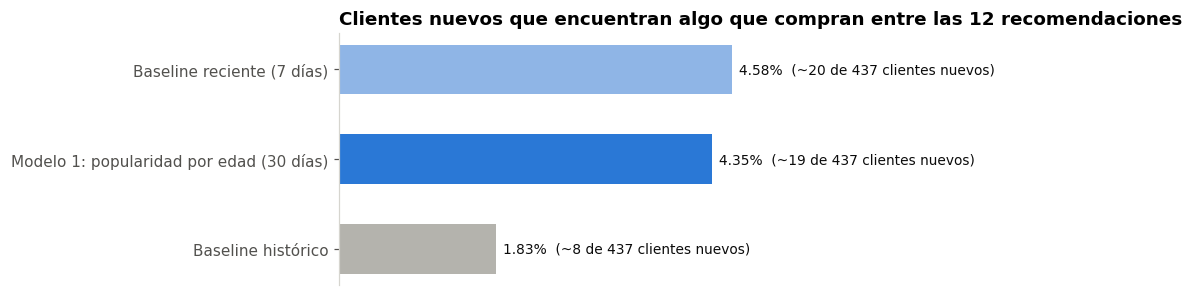

In [20]:
frios_res = resumen[resumen["Grupo"] == "Fríos"].sort_values("Hit Rate@12 (%)")
fig, ax = plt.subplots(figsize=(9, 2.8))
colores = [AZUL if m == NOMBRE_M1 else (GRIS if m == NOMBRE_HIST else "#8fb5e6") for m in frios_res["Modelo"]]
barras = ax.barh(frios_res["Modelo"], frios_res["Hit Rate@12 (%)"], color=colores, height=0.55)
for b, n in zip(barras, frios_res["Clientes con acierto"]):
    ax.text(b.get_width() + 0.08, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}%  (~{n} de {len(test_frios)} clientes nuevos)", va="center", fontsize=9, color=TEXTO)
ax.set_xlim(0, frios_res["Hit Rate@12 (%)"].max() * 1.6)
ax.grid(False); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Clientes nuevos que encuentran algo que compran entre las 12 recomendaciones")
fig.tight_layout()
guardar(fig, "07_resumen_frios")
plt.show()

---
# 6. Conclusiones, recomendaciones y próximos pasos

## Conclusiones
1. **Quedó definida la vara común del proyecto:** corte temporal sin fuga de información, métricas verificadas y un baseline oficial (**popularidad 7 días: MAP@12 = 0,0083; Hit Rate@12 = 6,97% / 4,58% en fríos**).
2. **La recencia es la señal más fuerte disponible hoy:** lo más vendido de la última semana triplica al histórico. Confirma la estacionalidad del EDA.
3. **El cold start es el desafío central:** los clientes nuevos (10,5% de los compradores semanales) aciertan menos que el promedio con cualquier estrategia de popularidad.
4. **Modelo 1 (edad):** ver el veredicto de la sección 4.4 y su intervalo de confianza en la 4.5.
5. **Una métrica no alcanza:** MAP@12 decide, Hit Rate@12 y Recall@12 traducen a KPIs del negocio (conversión y productos por pedido), y la diversidad muestra el costo de recomendar siempre lo mismo.

## 💼 Recomendaciones para H&M (aporte a las 7 recomendaciones del proyecto)
1. **Actualizar semanalmente** la lista de "más vendidos" que se muestra a clientes nuevos (mejora inmediata, sin costo).
2. **Pedir la edad en el registro** (o hacerla más visible): es la única pista sobre un cliente nuevo y habilita personalización desde la primera visita.
3. **Priorizar el orden de las primeras posiciones** del carrusel: en el celular se ven ~4 prendas; el ranking importa tanto como el acierto.
4. **No mostrar a todos las mismas 12 prendas:** concentra la visibilidad y el riesgo de quiebre de stock; la personalización reparte la demanda en más productos.

## ⚠️ Limitaciones
- **437 clientes fríos** en el test: los resultados en ese grupo tienen alta variabilidad.
- **Muestra del 10%:** las cifras por cliente son confiables; las de artículos están algo infladas por el muestreo (EDA).
- **Evaluación offline:** aproxima la conversión, pero el impacto real se confirma con un **test A/B** al implementar.
- **Mercado del hemisferio norte:** las temporadas no coinciden con las de Sudamérica.

## 🚀 Próximos pasos
| Paso | Por qué | Responde |
|---|---|---|
| **Modelo de contenido** (no supervisado): similitud por atributos de producto | Puede recomendar prendas nuevas (techo del 3,7%) | Punto 7 |
| **Co-compra** (no supervisado): "quienes compraron esto, también compraron…" | Aprovecha la primera compra de clientes con 1–2 compras | — |
| **Fríos simulados** | Más casos para evaluar modelos que usan historial | Punto 6 |
| **Ranker supervisado** (probabilidad de compra) | Combina recencia, edad, contenido y co-compra | H3 |
| **Análisis de costos y retorno** | Demostrar recupero de la inversión en ≤ 6 meses | Viabilidad económica |